# A história dos indicadores (2015 a 2026)

Notebook de demonstração do `projeto_pipeline_etl`. Ele **não** acessa APIs: lê só a saída final
do pipeline, `data/processed/indicadores_mensal.parquet`, como faria qualquer consumidor dos dados.

Perguntas:
1. Quando a inflação ficou fora da meta?
2. Como a Selic reagiu, e o que isso fez com o juro real?
3. O que aconteceu com o dólar?
4. O mercado acerta a inflação de 12 meses à frente?

Fontes: Banco Central (SGS e Boletim Focus) e ANBIMA. Método em `docs/arquitetura.md`.

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

ARQUIVO = Path("..") / "data" / "processed" / "indicadores_mensal.parquet"
mart = pd.read_parquet(ARQUIVO)
mart["primeiro_dia_mes"] = pd.to_datetime(mart["primeiro_dia_mes"])
mart = mart.sort_values("primeiro_dia_mes").set_index("primeiro_dia_mes")

# Cores validadas para fundo claro (validador de paleta: luminosidade, daltonismo, contraste)
COR = {"selic": "#2a78d6", "ipca": "#a86b00", "juro_real": "#c03d73", "dolar": "#0f8299"}
TEXTO, TEXTO_SEC, GRADE = "#1b1d24", "#555b6e", "#e1e3ea"

plt.rcParams.update(
    {
        "figure.figsize": (11, 4.2),
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": "#c3c2b7",
        "axes.grid": True,
        "grid.color": GRADE,
        "grid.linewidth": 0.8,
        "axes.axisbelow": True,
        "axes.titleweight": "bold",
        "axes.titlesize": 12,
        "axes.titlelocation": "left",
        "axes.labelcolor": TEXTO_SEC,
        "xtick.color": TEXTO_SEC,
        "ytick.color": TEXTO_SEC,
        "lines.linewidth": 2,
        "legend.frameon": False,
    }
)


def eixo_anual(ax):
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))


def rotulo_final(ax, serie, cor, sufixo="%", casas=2):
    serie = serie.dropna()
    x, y = serie.index[-1], serie.iloc[-1]
    texto = f"{y:.{casas}f}{sufixo}".replace(".", ",")
    ax.annotate(
        texto,
        (x, y),
        xytext=(6, 0),
        textcoords="offset points",
        va="center",
        color=TEXTO,
        fontsize=10,
    )
    ax.plot([x], [y], "o", color=cor, markersize=5)


print(f"{len(mart)} meses: {mart['ano_mes'].iloc[0]} a {mart['ano_mes'].iloc[-1]}")
colunas = ["ipca_acumulado_12m_pct", "meta_inflacao_pct", "selic_meta_fim_mes_pct", "dolar_fim_mes"]
mart.tail(3)[colunas]

143 meses: 2015-01 a 2026-11


,ipca_acumulado_12m_pct,meta_inflacao_pct,selic_meta_fim_mes_pct,dolar_fim_mes
primeiro_dia_mes,,,,
2026-09-01,4.58,3.0,13.75,5.1809
2026-10-01,NaN,3.0,13.75,5.4212
2026-11-01,NaN,3.0,13.75,5.5146


## 1. Quando a inflação ficou fora da meta?

A faixa cinza é o intervalo de tolerância da meta (centro pela série SGS 13521; tolerância de
2,0 p.p. até 2016 e 1,5 p.p. depois, Resolução CMN 4.419/2015). Pontos vermelhos: meses acima do teto.

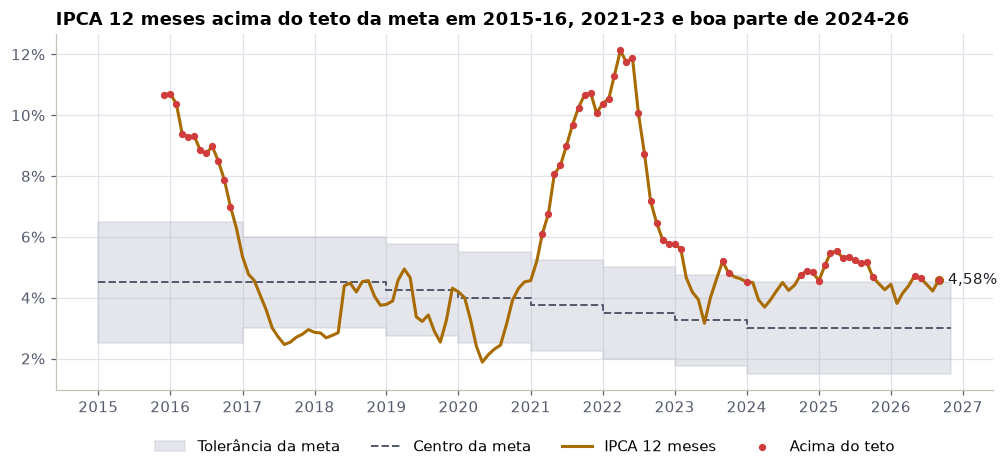

ano,2015,2016,2021,2022,2023,2024,2025,2026
meses acima do teto,1,11,10,12,4,4,10,3


In [2]:
tolerancia = mart["ano"].map(lambda ano: 2.0 if ano <= 2016 else 1.5)
teto = mart["meta_inflacao_pct"] + tolerancia
piso = mart["meta_inflacao_pct"] - tolerancia
ipca12 = mart["ipca_acumulado_12m_pct"]

fig, ax = plt.subplots()
ax.fill_between(
    mart.index, piso, teto, step="post", color="#b4b8c8", alpha=0.35, label="Tolerância da meta"
)
ax.step(
    mart.index,
    mart["meta_inflacao_pct"],
    where="post",
    color=TEXTO_SEC,
    linestyle="--",
    linewidth=1.3,
    label="Centro da meta",
)
ax.plot(ipca12.index, ipca12, color=COR["ipca"], label="IPCA 12 meses")
acima = ipca12[ipca12 > teto]
ax.scatter(acima.index, acima, color="#d03b3b", s=14, zorder=3, label="Acima do teto")
rotulo_final(ax, ipca12, COR["ipca"])
ax.set_title("IPCA 12 meses acima do teto da meta em 2015-16, 2021-23 e boa parte de 2024-26")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
eixo_anual(ax)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncols=4)
plt.show()

resumo = (ipca12 > teto).groupby(mart["ano"]).sum().rename("meses acima do teto")
resumo[resumo > 0].to_frame().T

**O que os dados mostram:** o IPCA 12 meses passou de 10% em 2015-2016 e em 2021-2022
(pico de 12,13% em abril de 2022), muito acima do teto, e voltou a ficar acima do teto em boa
parte de 2024 a 2026. Em 2017 ficou **abaixo do piso**. Fechamentos de ano (dezembro) acima do teto:
2015, 2021, 2022 e 2024; abaixo do piso: 2017.

## 2. Como a Selic reagiu? E o juro real?

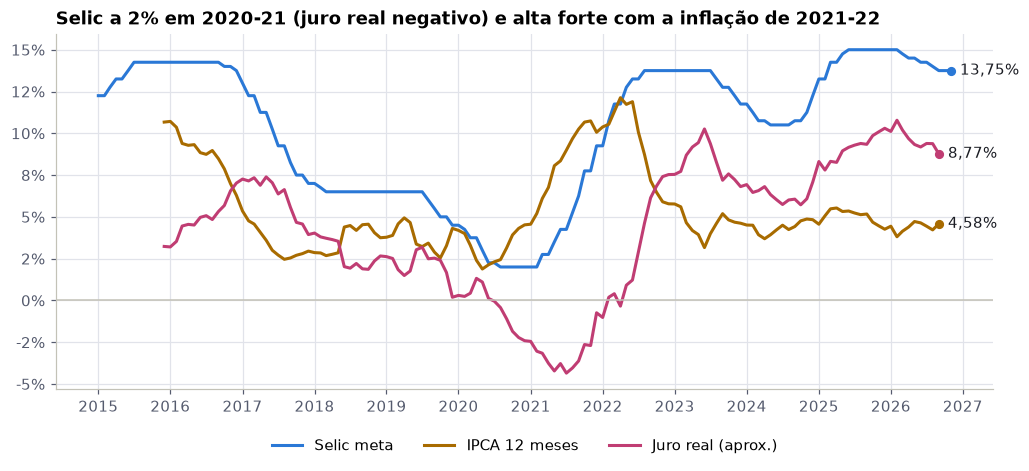

Juro real negativo em 20 meses: de 2020-07 a 2022-04
Selic mínima: 2.00% | máxima: 15.00%


In [3]:
fig, ax = plt.subplots()
series = [
    ("selic_meta_fim_mes_pct", "Selic meta", COR["selic"]),
    ("ipca_acumulado_12m_pct", "IPCA 12 meses", COR["ipca"]),
    ("juro_real_12m_pct", "Juro real (aprox.)", COR["juro_real"]),
]
for coluna, nome, cor in series:
    ax.plot(mart.index, mart[coluna], color=cor, label=nome)
    rotulo_final(ax, mart[coluna], cor)
ax.axhline(0, color="#c3c2b7", linewidth=1)
ax.set_title("Selic a 2% em 2020-21 (juro real negativo) e alta forte com a inflação de 2021-22")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
eixo_anual(ax)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncols=3)
plt.show()

negativo = mart.loc[mart["juro_real_12m_pct"] < 0, "ano_mes"]
print(f"Juro real negativo em {len(negativo)} meses: de {negativo.iloc[0]} a {negativo.iloc[-1]}")
selic = mart["selic_meta_fim_mes_pct"]
print(f"Selic mínima: {selic.min():.2f}% | máxima: {selic.max():.2f}%")

**O que os dados mostram:** a Selic meta caiu de 14,25% (2015-16) para 2% (2020-21), quando
ficou abaixo da inflação e o juro real ficou negativo. Depois subiu rápido, acompanhando o IPCA,
e chegou a 15% em 2025, a máxima da série.
O juro real aqui é uma aproximação: compara a Selic vigente com a inflação **passada** de 12 meses.

## 3. O que aconteceu com o dólar?

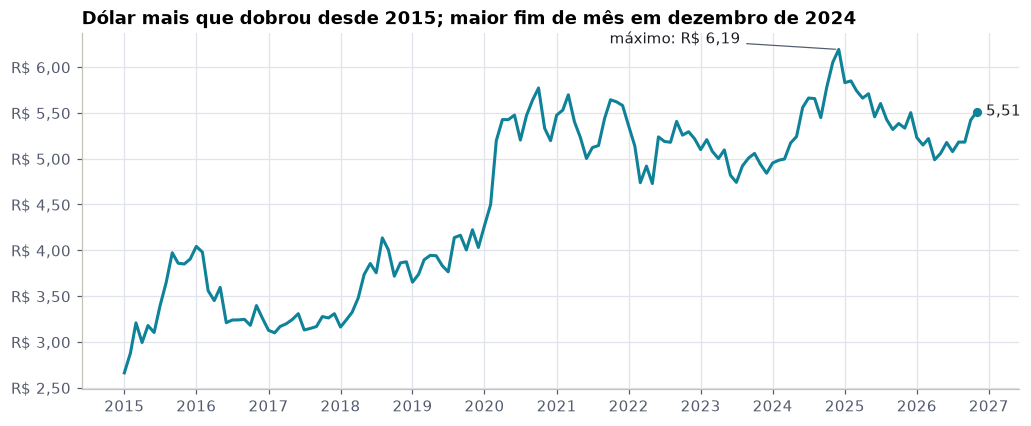

Maior alta mensal: 15.56% (2020-03)
Maior queda mensal: -10.72% (2016-06)


In [4]:
dolar = mart["dolar_fim_mes"]
fig, ax = plt.subplots()
ax.plot(dolar.index, dolar, color=COR["dolar"], label="Dólar fim do mês")
maior = dolar.idxmax()
texto_max = f"máximo: R$ {dolar.max():.2f}".replace(".", ",")
ax.annotate(
    texto_max,
    (maior, dolar.max()),
    xytext=(-150, 4),
    textcoords="offset points",
    color=TEXTO,
    fontsize=10,
    arrowprops=dict(arrowstyle="-", color=TEXTO_SEC, linewidth=0.8),
)
rotulo_final(ax, dolar, COR["dolar"], sufixo="", casas=2)
ax.set_title("Dólar mais que dobrou desde 2015; maior fim de mês em dezembro de 2024")
ax.yaxis.set_major_formatter(lambda v, _: f"R$ {v:.2f}".replace(".", ","))
eixo_anual(ax)
plt.show()

variacao = mart["dolar_variacao_mes_pct"]
print(f"Maior alta mensal: {variacao.max():.2f}% ({mart.loc[variacao.idxmax(), 'ano_mes']})")
print(f"Maior queda mensal: {variacao.min():.2f}% ({mart.loc[variacao.idxmin(), 'ano_mes']})")

**O que os dados mostram:** o dólar saiu de cerca de R$ 2,66 no início de 2015 para o maior
fim de mês da série em dezembro de 2024 (R$ 6,19). Variações mensais de 5% ou mais aparecem várias
vezes: são os choques cambiais que o painel sinaliza como alerta.

## 4. O mercado acerta a inflação de 12 meses à frente?

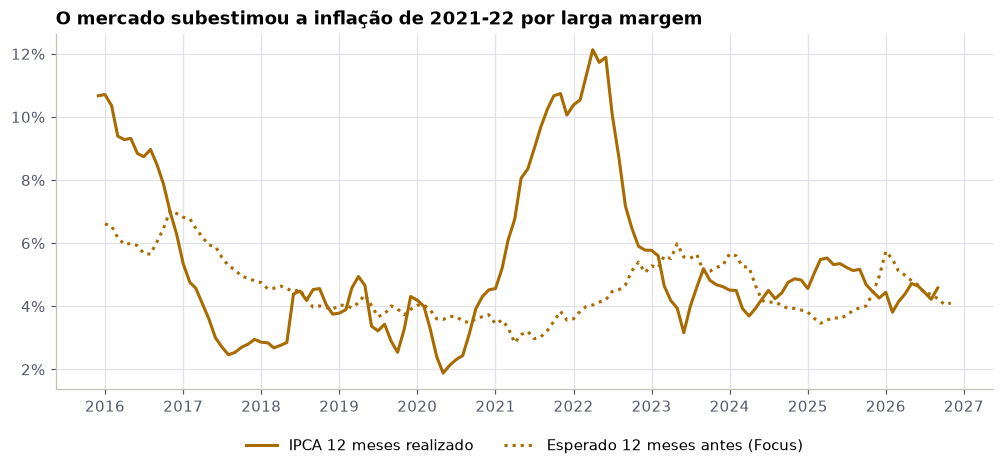

Meses comparados: 129 | erro médio absoluto: 1.91 p.p.
Maior surpresa para cima: 8.09 p.p. (2022-04)
Inflação acima do esperado em 68 de 129 meses


In [5]:
esperado = mart["expectativa_ipca_12m_pct"].shift(12)  # o que o Focus esperava 12 meses antes
realizado = mart["ipca_acumulado_12m_pct"]
erro = (realizado - esperado).dropna()

fig, ax = plt.subplots()
ax.plot(realizado.index, realizado, color=COR["ipca"], label="IPCA 12 meses realizado")
ax.plot(
    esperado.index,
    esperado,
    color=COR["ipca"],
    linestyle=":",
    label="Esperado 12 meses antes (Focus)",
)
ax.set_title("O mercado subestimou a inflação de 2021-22 por larga margem")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
eixo_anual(ax)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncols=2)
plt.show()

print(f"Meses comparados: {len(erro)} | erro médio absoluto: {erro.abs().mean():.2f} p.p.")
print(f"Maior surpresa para cima: {erro.max():.2f} p.p. ({mart.loc[erro.idxmax(), 'ano_mes']})")
print(f"Inflação acima do esperado em {int((erro > 0).sum())} de {len(erro)} meses")

**O que os dados mostram:** a expectativa de 12 meses à frente (mediana do Boletim Focus)
fica perto do realizado em períodos calmos, mas errou por vários pontos percentuais quando a inflação
disparou em 2021-2022.

## Conclusão
- A inflação passou boa parte do período fora da faixa da meta: para cima (2015-16, 2021-23 e boa
  parte de 2024-26) e para baixo (2017).
- A Selic seguiu a inflação com atraso; o juro real ficou negativo entre 2020 e 2022.
- O dólar mais que dobrou no período.
- As expectativas de mercado erram mais justamente quando a inflação muda de patamar.

Todos os números vêm da mart. Para explorar outros períodos, use o painel (`streamlit run app.py`).